<a href="https://colab.research.google.com/github/Hammad-vibes/FlyRank-Internship/blob/main/work/notebooks/capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone — Flagging Pages Likely to Lose Clicks

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Hammad-vibes/FlyRank-Internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This notebook mirrors the deployed paper section by section and **regenerates every number and chart the paper shows**. Lane: Refresh / Content Opportunity Scoring. One month (March 2026), directional results only.

Built on the FlyRank ML Internship dataset (https://flyrank.ai).

## 1. Question

**Decision this supports:** a content team cannot refresh every page at once, so which pages should be reviewed first?

**Question:** using only what is known by mid-month (1-15 March), can we rank pages so the top of the list holds more pages that lose clicks in 16-31 March than chance would?

**Prediction target:** decline = clicks in 16-31 March below 80% of clicks in 1-15 March, among pages with at least 5 clicks in the first half. This is a decision-support proxy, not a measure of content quality, and it says nothing about what *caused* a decline.

## 2. Data

Table: `fact_content_daily_performance`, partition `month=2026-03`, only rows where Search Console data is available (`IS TRUE`). One row in the warehouse = one date x one client x one content item. The model row is one content item (within one client) summarised over each half of the month. Excluded: pages with fewer than 5 h1 clicks (the ratio is too noisy), rows missing a feature, all GA4 / AI-referral columns (other lanes, sparse), and the final month June 2026 (sealed test month). The code cell prints the sizes used in the paper.

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
import duckdb, numpy as np, pandas as pd, json, os
import matplotlib.pyplot as plt
from google.colab import userdata

con = duckdb.connect()
con.execute(f"CREATE SECRET (TYPE huggingface, TOKEN '{userdata.get('HF_TOKEN')}')")
MAR = "hf://datasets/FlyRank/internship-warehouse/fact_content_daily_performance/month=2026-03/data_0.parquet"
con.execute(f"CREATE VIEW mar AS SELECT * FROM read_parquet('{MAR}')")

sizes = con.sql("""
SELECT COUNT(*) AS march_rows,
       COUNT(*) FILTER (WHERE gsc_data_available IS TRUE) AS gsc_available_rows,
       COUNT(DISTINCT client_hash_id) AS clients,
       COUNT(DISTINCT content_hash_id) AS content_items
FROM mar
""").df()
display(sizes)

frame = con.sql("""
SELECT client_hash_id, content_hash_id,
  SUM(gsc_impressions)  FILTER (WHERE report_date <= DATE '2026-03-15') AS impressions_h1,
  SUM(gsc_clicks)       FILTER (WHERE report_date <= DATE '2026-03-15') AS clicks_h1,
  AVG(gsc_avg_position) FILTER (WHERE report_date <= DATE '2026-03-15') AS avg_position_h1,
  COUNT(*) FILTER (WHERE report_date <= DATE '2026-03-15' AND gsc_impressions > 0) AS active_days_h1,
  SUM(gsc_clicks)       FILTER (WHERE report_date >  DATE '2026-03-15') AS clicks_h2
FROM mar
WHERE gsc_data_available IS TRUE
GROUP BY 1, 2
""").df()

df = frame.copy()
df["h2_missing"] = df["clicks_h2"].isna()
df["clicks_h2"] = df["clicks_h2"].fillna(0)
df["ctr_h1"] = df["clicks_h1"] / df["impressions_h1"].replace(0, np.nan)
FEATURES = ["impressions_h1", "clicks_h1", "ctr_h1", "avg_position_h1", "active_days_h1"]
df = df[df["clicks_h1"] >= 5].dropna(subset=FEATURES).copy()
df["label"] = (df["clicks_h2"] < 0.8 * df["clicks_h1"]).astype(int)
df = df.reset_index(drop=True)

print("pages used:", len(df), "| clients:", df["client_hash_id"].nunique(), "| decline rate:", round(df["label"].mean(), 3))
print("pages with no h2 rows at all:", int(df["h2_missing"].sum()))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,march_rows,gsc_available_rows,clients,content_items
0,9841378,3611061,55,331437


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

pages used: 17431 | clients: 29 | decline rate: 0.442
pages with no h2 rows at all: 1


## 3. Methodology

- **Features (5, all from 1-15 March):** impressions, clicks, CTR, average position, active days.
- **Baseline:** rank pages by lowest h1 impressions (fewer impressions = higher risk). No training needed.
- **Models:** logistic regression (log-scaled features), decision tree (depth 3), histogram gradient boosting (depth 3, regularised).
- **Validation:** 5-fold split **grouped by client** (honest), with a random 5-fold split shown next to it only to measure how optimistic a random split would be. Every method is scored on the same out-of-fold rows.
- **Metrics:** ROC-AUC, PR-AUC (against the base decline rate) and the decline rate among the top-10% flagged pages.
- **Leakage checks:** column windows asserted in code, univariate AUC, shuffled-label test, deliberate-leak experiment, and a drop-the-click-features test.

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
from sklearn.model_selection import StratifiedKFold, GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.metrics import roc_auc_score, average_precision_score

assert not ({"label", "clicks_h2", "h2_missing"} & set(FEATURES)), "label/future column in FEATURES"
y = df["label"].values
groups = df["client_hash_id"].values
X = df[FEATURES]

rand_folds  = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(df, y))
group_folds = list(GroupKFold(n_splits=5).split(df, y, groups))
for tr, te in group_folds:
    assert set(groups[tr]).isdisjoint(groups[te]), "client leaked across train/test"

models = {
    "logistic regression": lambda: make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=1000)),
    "decision tree (depth 3)": lambda: DecisionTreeClassifier(max_depth=3, min_samples_leaf=200, random_state=42),
    "gradient boosting": lambda: HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150,
                                                               min_samples_leaf=100, l2_regularization=1.0, random_state=42),
}
BASE = "baseline (low impressions)"

def oof(folds, make_model, Xm=None, yv=None):
    Xm = X if Xm is None else Xm; yv = y if yv is None else yv
    s = np.zeros(len(Xm))
    for tr, te in folds:
        m = make_model().fit(Xm.iloc[tr], yv[tr]); s[te] = m.predict_proba(Xm.iloc[te])[:, 1]
    return s

def top_rate(s, y_, frac=0.10):
    return y_[s >= np.quantile(s, 1 - frac)].mean()

scores = {}
for split, folds in [("random", rand_folds), ("grouped", group_folds)]:
    sc = {BASE: -df["impressions_h1"].values}
    for name, mk in models.items():
        sc[name] = oof(folds, mk)
    scores[split] = sc
print("models trained on both splits")

models trained on both splits


## 4. Results (vs baseline, same split)

The table and three figures below are what the paper embeds. The figures are saved to `work/outputs/figures/` so they can be copied into the paper's `assets/` folder.

all-pages decline rate (dumb guess for PR-AUC and top-10%): 0.442


,split,method,ROC-AUC,fold std,PR-AUC,top-10% decline rate
0,random,baseline (low impressions),0.549,0.008,0.484,0.530
1,random,logistic regression,0.595,0.006,0.521,0.569
2,random,decision tree (depth 3),0.587,0.007,0.507,0.552
3,random,gradient boosting,0.610,0.008,0.530,0.582
4,grouped,baseline (low impressions),0.549,0.026,0.484,0.530
5,grouped,logistic regression,0.586,0.036,0.513,0.562
6,grouped,decision tree (depth 3),0.554,0.024,0.483,0.514
7,grouped,gradient boosting,0.572,0.028,0.503,0.564



grouped split, folds where each model beats the baseline (of 5): {'logistic regression': 5, 'decision tree (depth 3)': 3, 'gradient boosting': 4}


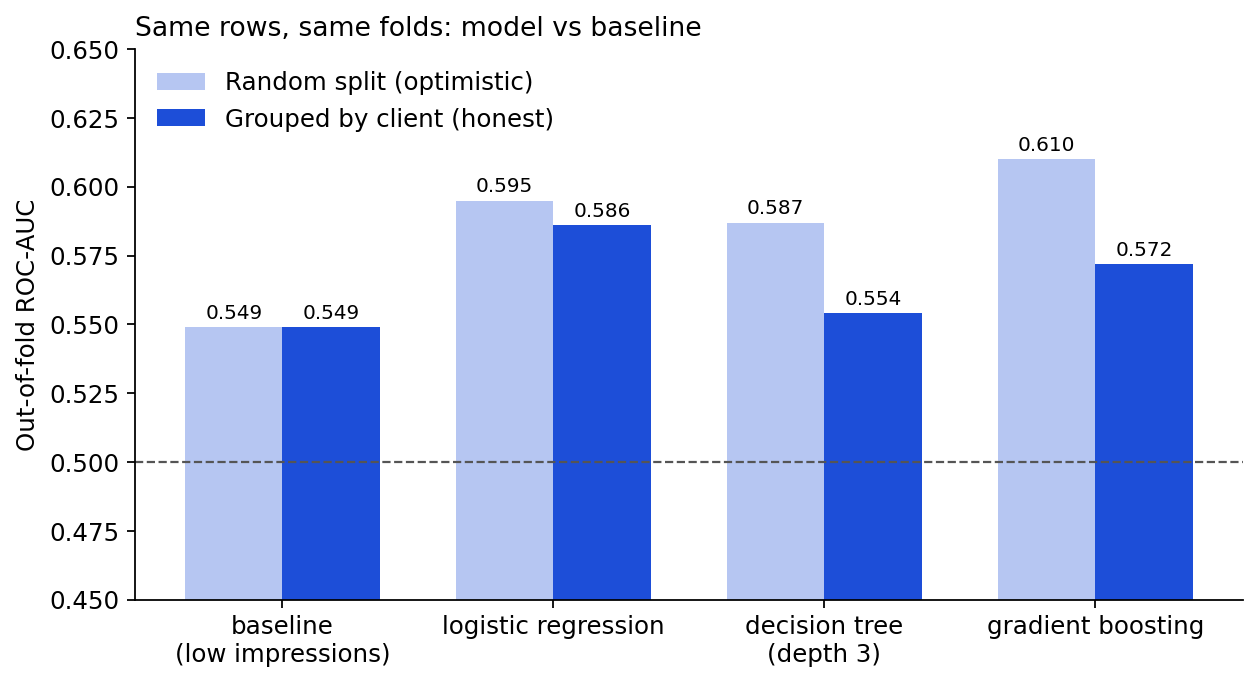

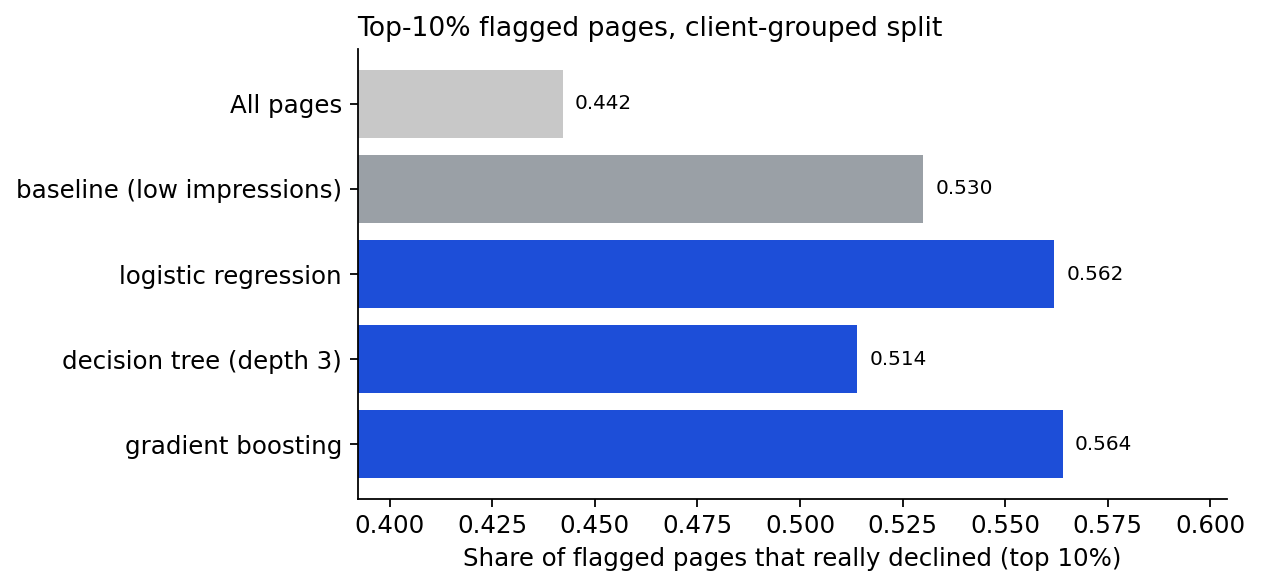

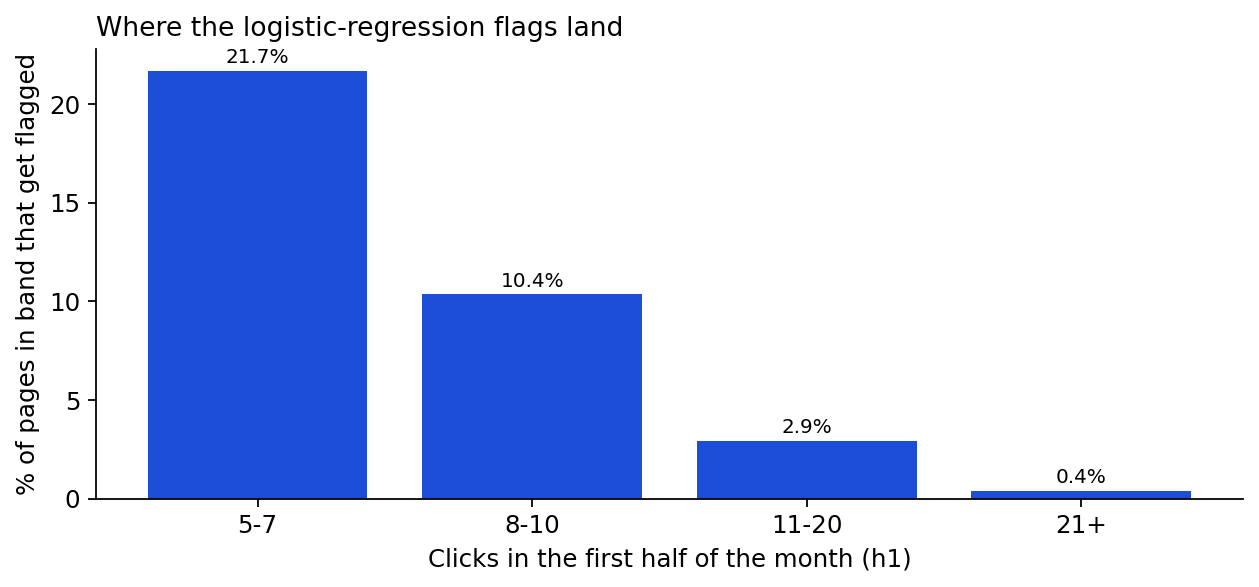

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
rows = []
for split, folds in [("random", rand_folds), ("grouped", group_folds)]:
    for name, s in scores[split].items():
        fold_auc = [roc_auc_score(y[te], s[te]) for _, te in folds]
        rows.append({"split": split, "method": name, "ROC-AUC": roc_auc_score(y, s), "fold std": np.std(fold_auc),
                     "PR-AUC": average_precision_score(y, s), "top-10% decline rate": top_rate(s, y)})
res = pd.DataFrame(rows).round(3)
print("all-pages decline rate (dumb guess for PR-AUC and top-10%):", round(y.mean(), 3))
display(res)

base_g = scores["grouped"][BASE]
wins = {}
for name in models:
    wins[name] = int(sum(roc_auc_score(y[te], scores["grouped"][name][te]) > roc_auc_score(y[te], base_g[te]) for _, te in group_folds))
print("\ngrouped split, folds where each model beats the baseline (of 5):", wins)

# ---- figures ----
os.makedirs("work/outputs/figures", exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
order = [BASE] + list(models)
g = res[res.split == "grouped"].set_index("method").loc[order]
r = res[res.split == "random"].set_index("method").loc[order]

fig, ax = plt.subplots(figsize=(8, 4.4), dpi=160)
x = np.arange(len(order)); w = 0.36
b1 = ax.bar(x - w/2, r["ROC-AUC"], w, color="#b6c6f2", label="Random split (optimistic)")
b2 = ax.bar(x + w/2, g["ROC-AUC"], w, color="#1d4ed8", label="Grouped by client (honest)")
ax.axhline(0.5, color="#555", ls="--", lw=1)
ax.set_ylim(0.45, max(r["ROC-AUC"].max(), g["ROC-AUC"].max()) + 0.04)
ax.set_xticks(x); ax.set_xticklabels([o.replace(" (", "\n(") for o in order]); ax.set_ylabel("Out-of-fold ROC-AUC")
for b in list(b1) + list(b2): ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.003, f"{b.get_height():.3f}", ha="center", fontsize=9)
ax.legend(frameon=False, loc="upper left"); ax.set_title("Same rows, same folds: model vs baseline", loc="left", fontsize=12)
plt.tight_layout(); plt.savefig("work/outputs/figures/results_chart.png"); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.8), dpi=160)
labels = ["All pages"] + order[:1] + order[1:]
vals = [y.mean()] + list(g["top-10% decline rate"])
cols = ["#c8c8c8", "#9aa0a6"] + ["#1d4ed8"] * len(models)
bars = ax.barh(labels[::-1], vals[::-1], color=cols[::-1])
ax.set_xlim(min(vals) - 0.05, max(vals) + 0.04); ax.set_xlabel("Share of flagged pages that really declined (top 10%)")
for bb in bars: ax.text(bb.get_width() + 0.003, bb.get_y() + bb.get_height()/2, f"{bb.get_width():.3f}", va="center", fontsize=9)
ax.set_title("Top-10% flagged pages, client-grouped split", loc="left", fontsize=12)
plt.tight_layout(); plt.savefig("work/outputs/figures/topk_chart.png"); plt.show()

d = df.copy()
d["score"] = scores["grouped"]["logistic regression"]
d["flagged"] = d["score"] >= d["score"].quantile(0.90)
d["band"] = pd.cut(d["clicks_h1"], [4, 7, 10, 20, np.inf], labels=["5-7", "8-10", "11-20", "21+"])
share = d.groupby("band", observed=True)["flagged"].mean() * 100
fig, ax = plt.subplots(figsize=(8, 3.8), dpi=160)
bars = ax.bar(share.index.astype(str), share.values, color="#1d4ed8")
for bb, v in zip(bars, share.values): ax.text(bb.get_x() + bb.get_width()/2, v + 0.4, f"{v:.1f}%", ha="center", fontsize=9)
ax.set_xlabel("Clicks in the first half of the month (h1)"); ax.set_ylabel("% of pages in band that get flagged")
ax.set_title("Where the logistic-regression flags land", loc="left", fontsize=12)
plt.tight_layout(); plt.savefig("work/outputs/figures/error_chart.png"); plt.show()

**Reading the results.** Under the client-grouped split, compare each model with the baseline on ROC-AUC, on the top-10% decline rate and on the number of folds won. A gain smaller than the fold-to-fold spread (the `fold std` column) is read as directional only. The random split rows show how much a random split flatters each model. The printed numbers are the ones to copy into the paper.

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# leakage audit on the final feature set
uni = {f: max(roc_auc_score(y, df[f]), 1 - roc_auc_score(y, df[f])) for f in FEATURES}
print("1) univariate ROC-AUC per feature (0.5 = no signal):"); print(pd.Series(uni).round(3).to_string())

y_shuf = np.random.RandomState(0).permutation(y)
auc_shuf = roc_auc_score(y_shuf, oof(group_folds, models["logistic regression"], yv=y_shuf))
print("\n2) shuffled-label ROC-AUC:", round(auc_shuf, 3), "(about 0.5 = no sign of pipeline leakage)")

honest = roc_auc_score(y, scores["grouped"]["logistic regression"])
df["leak_clicks_h2"] = df["clicks_h2"]
leaky = roc_auc_score(y, oof(group_folds, models["logistic regression"], Xm=df[FEATURES + ["leak_clicks_h2"]]))
df = df.drop(columns="leak_clicks_h2")
print("\n3) deliberate leak: honest", round(honest, 3), "-> with future clicks", round(leaky, 3), "-> removed again (number kept:", round(honest, 3), ")")

no_click = roc_auc_score(y, oof(group_folds, models["logistic regression"], Xm=df[["impressions_h1", "avg_position_h1", "active_days_h1"]]))
print("\n4) without clicks_h1 and ctr_h1:", round(no_click, 3), "| all five:", round(honest, 3))

1) univariate ROC-AUC per feature (0.5 = no signal):
impressions_h1     0.549
clicks_h1          0.542
ctr_h1             0.511
avg_position_h1    0.536
active_days_h1     0.539

2) shuffled-label ROC-AUC: 0.498 (about 0.5 = no sign of pipeline leakage)

3) deliberate leak: honest 0.586 -> with future clicks 1.0 -> removed again (number kept: 0.586 )

4) without clicks_h1 and ctr_h1: 0.586 | all five: 0.586


## 5. Limitations

- One month, split inside the month (features 1-15 March, label 16-31 March). Not a test on a different month, so it cannot show the pattern holds elsewhere.
- Weak in absolute terms: every model is expected to stay under ROC-AUC 0.6, so the score is decision-support for where to look first, not a reliable predictor.
- Prediction, not cause: nothing here shows that refreshing a page changes its clicks, and nothing here says anything about how Google ranks pages.
- Pages with 5-7 clicks dominate the flags and have the noisiest label; one possible explanation (not tested) is that pages near the click floor tend to fall back.
- A few clients make up a large share of the data and of the flags.
- Features cannot see content age, seasonality or ranking changes.
- The leakage checks find what I thought to look for; they do not prove nothing leaks.

## 6. Ranked recommendations

The code cell below prints the evidence behind each recommendation from this run, so the playbook in the paper can quote real numbers. The ranking is by how much it changes the decision, then by how well the evidence supports it.

1. Use the logistic-regression score only as a triage list (look first, not "will decline").
2. Do not act on flags from 5-7-click pages alone.
3. Re-test on a different month before relying on the score.
4. Always validate grouped by client.
5. Try features the model cannot see today (content age, last refresh date, seasonality) before more complex models.

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
lr = res[(res.split == "grouped") & (res.method == "logistic regression")].iloc[0]
lr_r = res[(res.split == "random") & (res.method == "logistic regression")].iloc[0]
fl = d[d["flagged"]]
evidence = {
    "1) triage list: top-10% decline rate vs all pages": (round(float(lr["top-10% decline rate"]), 3), round(float(y.mean()), 3)),
    "2) share of flagged pages with only 5-7 h1 clicks": round(float((fl["band"] == "5-7").mean()), 3),
    "3) one month only: months tested": 1,
    "4) random-minus-grouped ROC-AUC (logistic regression)": round(float(lr_r["ROC-AUC"] - lr["ROC-AUC"]), 3),
    "5) flagged share from top 3 clients": round(float(fl["client_hash_id"].value_counts(normalize=True).head(3).sum()), 3),
}
for k, v in evidence.items():
    print(f"{k:60} {v}")

1) triage list: top-10% decline rate vs all pages            (0.562, 0.442)
2) share of flagged pages with only 5-7 h1 clicks            0.732
3) one month only: months tested                             1
4) random-minus-grouped ROC-AUC (logistic regression)        0.009
5) flagged share from top 3 clients                          0.581


## 7. Artifacts the paper embeds

The cell below writes a small metrics file (the run's receipt). Copy the three PNGs from `work/outputs/figures/` into the paper's `assets/` folder if their numbers differ from the ones currently in the paper, and update the paper's numbers to match this run. The paper and this notebook must agree.

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
metrics = {
    "month": "2026-03", "pages_used": int(len(df)), "clients": int(df["client_hash_id"].nunique()),
    "all_pages_decline_rate": round(float(y.mean()), 3),
    "results": json.loads(res.to_json(orient="records")),
    "folds_beating_baseline_grouped": wins,
    "shuffled_label_auc": round(float(auc_shuf), 3),
    "deliberate_leak_auc": round(float(leaky), 3),
    "honest_auc": round(float(honest), 3),
}
os.makedirs("work/outputs", exist_ok=True)
with open("work/outputs/capstone_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
print("written: work/outputs/capstone_metrics.json")
print("figures:", sorted(os.listdir("work/outputs/figures")))

written: work/outputs/capstone_metrics.json
figures: ['error_chart.png', 'results_chart.png', 'topk_chart.png']


## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Paper numbers match this run; `submission/paper_url.txt` holds the live paper URL
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.

## 5-minute demo outline

**The case in one line:** a content team can only review a few pages a week; can early-month search data tell them which ones to look at first?

| Time | What I say / show |
|---|---|
| 0:00 to 0:45 | **Question.** The decision: which already-published pages get reviewed for refresh first. Prediction target: a page "declines" if clicks in 16-31 March fall below 80% of clicks in 1-15 March (pages with at least 5 clicks). One month, March 2026, 17,431 pages from 29 clients (anonymised). |
| 0:45 to 2:00 | **Method.** Five features from days 1-15 only (impressions, clicks, CTR, position, active days). Baseline: rank by lowest impressions, the simplest hand-written rule. Models: logistic regression, a shallow tree, shallow gradient boosting. Validation grouped by client, so no client appears in both train and test. Leakage checks: shuffled labels (0.498), and a deliberate leak (future clicks) that jumped the score to about 1.0 and was then removed. |
| 2:00 to 3:15 | **One chart: `results_chart.png`.** Same rows, same folds, baseline vs three models, random split next to the honest grouped split. Point out that the random split is higher for every model, so it would have flattered the result. |
| 3:15 to 4:15 | **One honest result.** Under the grouped split, logistic regression reached ROC-AUC 0.586 vs 0.549 for the baseline and won 5 of 5 folds; its top-10% flagged pages declined 56.2% of the time vs 44.2% for all pages. The gain is about the size of the fold-to-fold noise and every model stays under 0.6, so I call it small and directional, decision-support, not a reliable predictor. One month only. |
| 4:15 to 5:00 | **One recommendation.** Use the score as a "look here first" triage list, and do not act on flags from pages with only 5-7 clicks alone (73% of flags are there and the label is noisiest). Next step before trusting it: repeat on a different month. |

**If asked:** it does not show that refreshing a page recovers clicks, and it says nothing about how search engines rank pages. Gradient boosting scored about the same as logistic regression, so I kept the readable model.

## Two shareable cuts

### Social post (methodology)

I tried to predict which web pages will lose search clicks next, using real (anonymised) search data. The part I learned the most from was validation, not modelling.

If you split rows randomly, pages from the same client land in both train and test, and every model looked better. When I held out whole clients instead, the scores dropped, the fancier models dropped the most, and plain logistic regression was the only one that beat my one-line baseline (lowest search volume) in every fold. I also added a "future clicks" column on purpose to watch the score jump to about 1.0, then deleted it.

Honest result: a small, directional improvement (ROC-AUC 0.586 vs 0.549), one month of data, so it works as a "look here first" list, not a predictor. Built on the FlyRank ML Internship dataset: https://flyrank.ai

#MachineLearning #SEO #DataScience

### Employer-facing summary (3 sentences)

I built a model that ranks web pages by how likely they are to lose search clicks in the second half of a month, validated so that no client appears in both training and testing, and compared it with a simple hand-written baseline. I used one month (March 2026) of real, anonymised Search Console data from the FlyRank ML Internship dataset: 17,431 pages from 29 clients. The best model (logistic regression) modestly beat the baseline (ROC-AUC 0.586 vs 0.549, ahead in all 5 folds), which I report as a small, directional gain useful for deciding where to look first, not as a reliable predictor, and I documented the limits, leakage checks and a ranked action playbook in a public paper.